# Final IDEC Training

This notebook trains the final Improved Deep Embedded Clustering (IDEC) model after completing experimental analysis and model selection.

The final model is trained using:

- the full dataset, without a train/validation split;
- the pretrained autoencoder encoder and decoder, both trainable during IDEC optimization;
- a fresh KMeans initialization fitted on the full-dataset pretrained embeddings;
- 5 clusters;
- the selected `alpha`;
- the selected learning rate;
- the selected target-distribution update interval;
- γ = 0.1;
- random seed 42 for the final training pipeline.

The resulting full-dataset cluster assignments are used for subsequent clustering evaluation, UMAP visualization, and cluster-profile analysis.

No hyperparameter selection is performed in this notebook. All hyperparameters are fixed based on the completed tuning experiments.

In [1]:
import random

import numpy as np
import pandas as pd
import torch

from sklearn.cluster import KMeans

import matplotlib.pyplot as plt

In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

In [3]:
# Final IDEC configuration

N_CLUSTERS = 5
ALPHA = 0.5
LEARNING_RATE = 3e-3
UPDATE_INTERVAL = 20
BATCH_SIZE = 256
MAX_EPOCHS = 50
N_INIT = 20
CLUSTERING_WEIGHT = 0.1

SEED = 42

config = {
    "dec": {
        "num_clusters": N_CLUSTERS,
        "alpha": ALPHA,
        "learning_rate": LEARNING_RATE,
        "update_interval": UPDATE_INTERVAL,
        "max_epochs": MAX_EPOCHS,
        "batch_size": BATCH_SIZE,
        "n_init": N_INIT,
        "encoder_frozen": False,
    },
    "idec": {
        "clustering_weight": CLUSTERING_WEIGHT,
    },
}

In [4]:
# Load the full dataset

X_scaled = pd.read_csv("../dataset/X_scaled.csv").values

print("X_scaled shape:", X_scaled.shape)

X_scaled shape: (99997, 7)


In [5]:
# Basic data sanity checks
print("Shape:", X_scaled.shape)
print("Dtype:", X_scaled.dtype)
print("Number of samples:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])

print("NaN values:", np.isnan(X_scaled).sum())
print("Infinite values:", np.isinf(X_scaled).sum())

EXPECTED_FEATURES = 7
assert X_scaled.shape[1] == EXPECTED_FEATURES
assert np.isfinite(X_scaled).all()

print("Data checks passed.")

Shape: (99997, 7)
Dtype: float64
Number of samples: 99997
Number of features: 7
NaN values: 0
Infinite values: 0
Data checks passed.


## Pretrained Autoencoder

The final IDEC model starts from the same pretrained autoencoder used
throughout the preceding experiments.

Unlike the frozen-encoder DEC formulation, both the encoder and decoder remain
trainable during IDEC optimization. The reconstruction term constrains the
latent representation while the KL-divergence term optimizes the clustering
assignments.


In [6]:
from src.dec.train_dec import train_idec

results = train_idec(
    X=X_scaled,
    ae_checkpoint_path=PROJECT_ROOT / "models" / "autoencoder_weights.pth",
    config=config,
    seed=SEED,
)

c:\uni-generall\term8\پروژه\Roommate-Compatibility-Analysis\dec_env\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\uni-generall\term8\پروژه\Roommate-Compatibility-Analysis\dec_env\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\uni-generall\term8\پروژه\Roommate-Compatibility-Analysis\dec_env\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\hp\AppData\Local\Programs\Py

Epoch 1/50, KL Loss = 0.0250, Reconstruction Loss = 0.1169
Epoch 2/50, KL Loss = 0.0202, Reconstruction Loss = 0.1110
Epoch 3/50, KL Loss = 0.0225, Reconstruction Loss = 0.1039
Epoch 4/50, KL Loss = 0.0217, Reconstruction Loss = 0.0988
Epoch 5/50, KL Loss = 0.0221, Reconstruction Loss = 0.0975
Epoch 6/50, KL Loss = 0.0203, Reconstruction Loss = 0.0957
Epoch 7/50, KL Loss = 0.0196, Reconstruction Loss = 0.0935
Epoch 8/50, KL Loss = 0.0197, Reconstruction Loss = 0.0931
Epoch 9/50, KL Loss = 0.0202, Reconstruction Loss = 0.0903
Epoch 10/50, KL Loss = 0.0208, Reconstruction Loss = 0.0889
Epoch 11/50, KL Loss = 0.0212, Reconstruction Loss = 0.0889
Epoch 12/50, KL Loss = 0.0205, Reconstruction Loss = 0.0881
Epoch 13/50, KL Loss = 0.0198, Reconstruction Loss = 0.0872
Epoch 14/50, KL Loss = 0.0201, Reconstruction Loss = 0.0871
Epoch 15/50, KL Loss = 0.0208, Reconstruction Loss = 0.0874
Epoch 16/50, KL Loss = 0.0211, Reconstruction Loss = 0.0875
Epoch 17/50, KL Loss = 0.0208, Reconstruction Los

In [7]:
from pathlib import Path
import numpy as np

# Create output directory
final_dir = Path(PROJECT_ROOT / "final_idec" / "model")
final_dir.mkdir(parents=True, exist_ok=True)

# Save final IDEC outputs
np.save(final_dir / "final_embeddings.npy", results["Z_full"])
np.save(final_dir / "final_labels.npy", results["full_labels"])
np.save(final_dir / "final_q.npy", results["q_full"])
np.save(final_dir / "final_p.npy", results["p_full"])
np.save(final_dir / "cluster_centers.npy", results["cluster_centers"])

# Save the initial pretrained embedding for representation-change analysis

np.save(final_dir / "initial_embeddings.npy", results["Z_initial"])

# Verify outputs
print("Embeddings shape:", results["Z_full"].shape)
print("Labels shape:", results["full_labels"].shape)
print("Q shape:", results["q_full"].shape)
print("P shape:", results["p_full"].shape)
print("Cluster centers shape:", results["cluster_centers"].shape)
print("Initial embeddings shape:", results["Z_initial"].shape)

print("Embeddings finite:", np.isfinite(results["Z_full"]).all())
print("Q finite:", np.isfinite(results["q_full"]).all())
print("P finite:", np.isfinite(results["p_full"]).all())
print("All outputs saved successfully.")

Embeddings shape: (99997, 5)
Labels shape: (99997,)
Q shape: (99997, 5)
P shape: (99997, 5)
Cluster centers shape: (5, 5)
Initial embeddings shape: (99997, 5)
Embeddings finite: True
Q finite: True
P finite: True
All outputs saved successfully.


In [8]:
import json
from pathlib import Path

cluster_profile_dir = Path("../final_idec/metrics/")
cluster_profile_dir.mkdir(parents=True, exist_ok=True)
history_path = cluster_profile_dir / "training_history.json"

training_history = {
    "train_kl": results["train_kl"],
    "train_reconstruction": results["train_reconstruction"],
    "epochs": len(results["train_kl"]),
    "update_interval": UPDATE_INTERVAL,
    "clustering_weight": CLUSTERING_WEIGHT,
}

with open(history_path, "w") as f:
    json.dump(training_history, f, indent=2)

print(f"Training history saved to: {history_path}")

Training history saved to: ..\final_idec\metrics\training_history.json


In [10]:
import json
from pathlib import Path

# Final cluster sizes

unique_labels, cluster_counts = np.unique(
    results["full_labels"],
    return_counts=True,
)

cluster_sizes = {
    int(label): int(count)
    for label, count in zip(unique_labels, cluster_counts)
}

min_size = min(cluster_sizes.values())
max_size = max(cluster_sizes.values())
imbalance_ratio = max_size / min_size

print("Final cluster sizes:")

for label in sorted(cluster_sizes):
    print(f"Cluster {label}: {cluster_sizes[label]}")

print(f"\nMinimum cluster size: {min_size}")
print(f"Maximum cluster size: {max_size}")
print(f"Imbalance ratio (max/min): {imbalance_ratio:.4f}")

# Save

output_dir = Path("../final_idec/cluster_profiles/")
output_dir.mkdir(parents=True, exist_ok=True)

cluster_sizes_path = output_dir / "cluster_sizes.json"

with open(cluster_sizes_path, "w") as f:
    json.dump(
        {
            "cluster_sizes": cluster_sizes,
            "minimum_cluster_size": min_size,
            "maximum_cluster_size": max_size,
            "imbalance_ratio": imbalance_ratio,
        },
        f,
        indent=2,
    )

print(f"\nCluster sizes saved to: {cluster_sizes_path}")

Final cluster sizes:
Cluster 0: 492
Cluster 1: 22916
Cluster 2: 25806
Cluster 3: 29657
Cluster 4: 21126

Minimum cluster size: 492
Maximum cluster size: 29657
Imbalance ratio (max/min): 60.2785

Cluster sizes saved to: ..\final_idec\cluster_profiles\cluster_sizes.json


In [11]:
from pathlib import Path

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)

# Final full-dataset representation and assignments

embeddings = results["Z_full"]
labels = results["full_labels"]

# Calculate internal clustering metrics

silhouette = silhouette_score(embeddings, labels)
davies_bouldin = davies_bouldin_score(embeddings, labels)
calinski_harabasz = calinski_harabasz_score(embeddings, labels)

print("Final clustering quality:")
print(f"Silhouette Score:        {silhouette:.6f}")
print(f"Davies-Bouldin Index:    {davies_bouldin:.6f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz:.6f}")

# Save metrics

output_dir = Path("../final_idec/metrics/")
output_dir.mkdir(parents=True, exist_ok=True)

metrics_path = output_dir / "metrics.json"

metrics = {
    "silhouette_score": float(silhouette),
    "davies_bouldin_index": float(davies_bouldin),
    "calinski_harabasz_score": float(calinski_harabasz),
}

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

print(f"\nMetrics saved to: {metrics_path}")

Final clustering quality:
Silhouette Score:        0.471818
Davies-Bouldin Index:    0.780245
Calinski-Harabasz Index: 138960.164908

Metrics saved to: ..\final_idec\metrics\metrics.json


In [12]:
import json
from pathlib import Path
import numpy as np

# Final soft assignments

q_full = results["q_full"]

# Same entropy definition used in the experiments

eps = 1e-10

entropy = -np.sum(
    q_full * np.log(q_full + eps),
    axis=1,
)

mean_entropy = float(np.mean(entropy))
std_entropy = float(np.std(entropy))

print("Final assignment entropy:")
print(f"Mean entropy: {mean_entropy:.6f}")
print(f"Std entropy:  {std_entropy:.6f}")

# Update and save metrics

output_dir = Path("../final_idec/metrics/")
output_dir.mkdir(parents=True, exist_ok=True)

metrics_path = output_dir / "metrics.json"

with open(metrics_path, "r") as f:
    metrics = json.load(f)

metrics["entropy_metrics"] = {
    "mean_entropy": mean_entropy,
    "std_entropy": std_entropy,
}

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

print(f"\nEntropy metrics saved to: {metrics_path}")

Final assignment entropy:
Mean entropy: 1.021665
Std entropy:  0.306902

Entropy metrics saved to: ..\final_idec\metrics\metrics.json


In [13]:
import json
from pathlib import Path
import numpy as np

train_kl = np.array(results["train_kl"], dtype=float)
train_reconstruction = np.array(
    results["train_reconstruction"],
    dtype=float,
)

kl_metrics = {
    "final_train_kl": float(train_kl[-1]),
    "minimum_train_kl": float(np.min(train_kl)),
    "minimum_train_kl_epoch": int(np.argmin(train_kl) + 1),
    "maximum_train_kl": float(np.max(train_kl)),
    "mean_train_kl": float(np.mean(train_kl)),
    "std_train_kl": float(np.std(train_kl)),
}

reconstruction_metrics = {
    "initial_reconstruction": float(train_reconstruction[0]),
    "final_reconstruction": float(train_reconstruction[-1]),
    "minimum_reconstruction": float(np.min(train_reconstruction)),
    "minimum_reconstruction_epoch": int(
        np.argmin(train_reconstruction) + 1
    ),
    "maximum_reconstruction": float(np.max(train_reconstruction)),
    "mean_reconstruction": float(np.mean(train_reconstruction)),
    "std_reconstruction": float(np.std(train_reconstruction)),
}

print("Final KL metrics:")

for key, value in kl_metrics.items():
    print(
        f"{key}: {value:.6f}"
        if isinstance(value, float)
        else f"{key}: {value}"
    )

print("\nFinal reconstruction metrics:")

for key, value in reconstruction_metrics.items():
    print(
        f"{key}: {value:.6f}"
        if isinstance(value, float)
        else f"{key}: {value}"
    )

# Save to metrics.json

output_dir = Path("../final_idec/metrics/")
output_dir.mkdir(parents=True, exist_ok=True)

metrics_path = output_dir / "metrics.json"

with open(metrics_path, "r") as f:
    metrics = json.load(f)

metrics["optimization_metrics"] = kl_metrics
metrics["reconstruction_metrics"] = reconstruction_metrics

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

print(f"\nOptimization metrics saved to: {metrics_path}")

Final KL metrics:
final_train_kl: 0.063870
minimum_train_kl: 0.019398
minimum_train_kl_epoch: 20
maximum_train_kl: 0.108931
mean_train_kl: 0.039949
std_train_kl: 0.023355

Final reconstruction metrics:
initial_reconstruction: 0.116856
final_reconstruction: 0.083671
minimum_reconstruction: 0.082661
minimum_reconstruction_epoch: 38
maximum_reconstruction: 0.116856
mean_reconstruction: 0.087819
std_reconstruction: 0.006887

Optimization metrics saved to: ..\final_idec\metrics\metrics.json


## UMAP visualization

UMAP is used only for visualization and interpretation of the learned embedding space. It is not involved in IDEC optimization or hyperparameter selection.

The final IDEC embeddings are projected into two dimensions using the established UMAP configuration with `n_components=2` and `random_state=42`. The resulting visualization is colored according to the final IDEC cluster assignments.

In [14]:
import numpy as np
import umap.umap_ as umap

# Load final embeddings and cluster labels

embeddings = np.load("../final_idec/model/final_embeddings.npy")
labels = np.load("../final_idec/model/final_labels.npy")

reducer = umap.UMAP(
    n_components=2,
    random_state=42,
)

embedding_2d = reducer.fit_transform(embeddings)

print("UMAP done.")
print("Original embeddings shape:", embeddings.shape)
print("UMAP embedding shape:", embedding_2d.shape)

# Save UMAP coordinates

np.save(
    "../final_idec/metrics/umap_embedding_2d.npy",
    embedding_2d,
)

print(
    "UMAP coordinates saved to: "
    "../final_idec/metrics/umap_embedding_2d.npy"
)

c:\uni-generall\term8\پروژه\Roommate-Compatibility-Analysis\dec_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\uni-generall\term8\پروژه\Roommate-Compatibility-Analysis\dec_env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP done.
Original embeddings shape: (99997, 5)
UMAP embedding shape: (99997, 2)
UMAP coordinates saved to: ../final_idec/metrics/umap_embedding_2d.npy


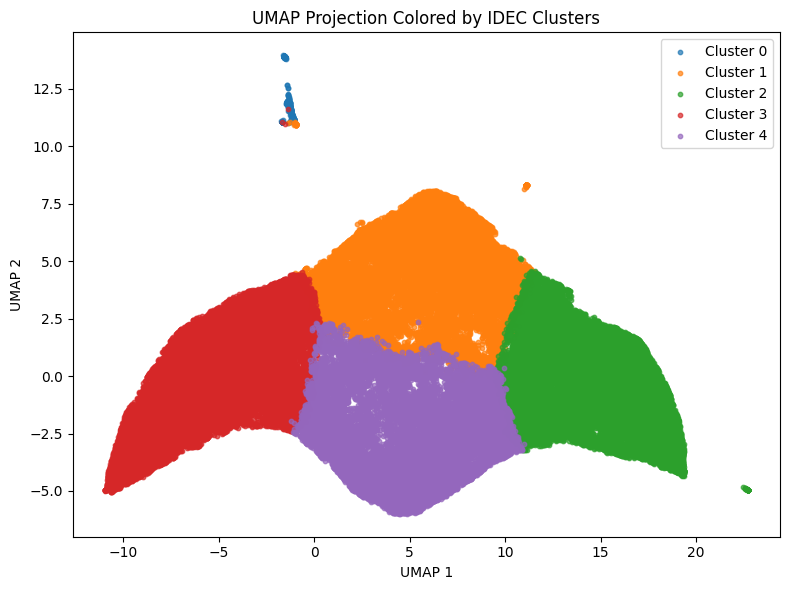

UMAP figure saved to: ..\final_idec\figures\umap_clusters.png


In [15]:
import matplotlib.pyplot as plt
from pathlib import Path

# Create figures directory

figures_dir = "../final_idec/figures"
Path(figures_dir).mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 6))

# Plot each cluster separately

for cluster_id in np.unique(labels):
    mask = labels == cluster_id

    plt.scatter(
        embedding_2d[mask, 0],
        embedding_2d[mask, 1],
        s=10,
        alpha=0.7,
        label=f"Cluster {cluster_id}",
    )

plt.title("UMAP Projection Colored by IDEC Clusters")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend()
plt.tight_layout()

output_path = Path(figures_dir) / "umap_clusters.png"

plt.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(f"UMAP figure saved to: {output_path}")

## Cluster profiles

Cluster profiling is performed using the original interpretable feature
representation rather than the UMAP coordinates.

For each final IDEC cluster, the mean and standard deviation of each original
feature are calculated and feature-level z-scores are computed relative to the
overall dataset. These z-scores are used to identify the features that are
relatively higher or lower in each cluster.

In [16]:
import numpy as np
import pandas as pd
from pathlib import Path

# Paths

cluster_profile_dir = Path("../final_idec/cluster_profiles/")
cluster_profile_dir.mkdir(parents=True, exist_ok=True)

# Load final labels

labels = np.load("../final_idec/model/final_labels.npy")

# Load original interpretable feature data

df = pd.read_excel("../dataset/compressed_features.xlsx")

df = df.dropna().reset_index(drop=True)

print("Profile data shape:", df.shape)
print("Labels shape:", labels.shape)

# Verify row alignment

if len(df) != len(labels):
    raise ValueError(
        f"Row mismatch: dataset has {len(df)} rows but "
        f"labels have {len(labels)} entries."
    )

# Cluster sizes

cluster_counts = (
    pd.Series(labels, name="cluster")
    .value_counts()
    .sort_index()
)

print("\nCluster sizes:")
print(cluster_counts)

cluster_counts.to_csv(
    cluster_profile_dir / "cluster_counts.csv",
    header=["size"],
)

# Select numerical features

df_num = df.select_dtypes(include=[np.number]).copy()

# Make sure the expected feature count is correct

print("\nNumber of numerical features:", df_num.shape[1])

df_num["cluster"] = labels

# Cluster means and standard deviations

cluster_means = df_num.groupby("cluster").mean()
cluster_stds = df_num.groupby("cluster").std()

# Feature-level z-scores relative to global population

features = df_num.drop(columns="cluster")

global_mean = features.mean()
global_std = features.std()

cluster_z = (
    (cluster_means - global_mean)
    / (global_std + 1e-12)
)

# Save complete profile tables

cluster_means.to_csv(
    cluster_profile_dir / "cluster_feature_mean.csv"
)

cluster_stds.to_csv(
    cluster_profile_dir / "cluster_feature_std.csv"
)

cluster_z.to_csv(
    cluster_profile_dir / "cluster_feature_zscore.csv"
)

# Extract top positive / negative characteristics

topk = 8
profiles = {}

for cluster_id in cluster_z.index:

    z_scores = cluster_z.loc[cluster_id]

    # Only genuinely above-average features

    top_pos = (
        z_scores[z_scores > 0]
        .sort_values(ascending=False)
        .head(topk)
    )

    # Only genuinely below-average features

    top_neg = (
        z_scores[z_scores < 0]
        .sort_values(ascending=True)
        .head(topk)
    )

    profiles[cluster_id] = {
        "top_pos": top_pos,
        "top_neg": top_neg,
    }


# Create readable profile text

def readable_profile(cluster_id, top_pos, top_neg, count):

    lines = []

    lines.append(f"Cluster {cluster_id} (N={count}):")

    lines.append("  Characteristics (higher than average):")

    if len(top_pos) == 0:
        lines.append("    - None")
    else:
        for feature, z in top_pos.items():
            lines.append(f"    - {feature}: z={z:.2f}")

    lines.append("  Characteristics (lower than average):")

    if len(top_neg) == 0:
        lines.append("    - None")
    else:
        for feature, z in top_neg.items():
            lines.append(f"    - {feature}: z={z:.2f}")

    return "\n".join(lines)


profiles_text = []

for cluster_id in sorted(profiles.keys()):

    top_pos = profiles[cluster_id]["top_pos"]
    top_neg = profiles[cluster_id]["top_neg"]

    text = readable_profile(
        cluster_id,
        top_pos,
        top_neg,
        int(cluster_counts.loc[cluster_id]),
    )

    profiles_text.append(text)


# Save readable profiles

profiles_path = cluster_profile_dir / "cluster_profiles.txt"

with open(
    profiles_path,
    "w",
    encoding="utf-8",
) as f:
    f.write("\n\n".join(profiles_text))


# Display profiles

print("\n" + "\n\n".join(profiles_text))

print("\nCluster profile artifacts saved:")
print(f"- {cluster_profile_dir / 'cluster_counts.csv'}")
print(f"- {cluster_profile_dir / 'cluster_feature_mean.csv'}")
print(f"- {cluster_profile_dir / 'cluster_feature_std.csv'}")
print(f"- {cluster_profile_dir / 'cluster_feature_zscore.csv'}")
print(f"- {profiles_path}")

Profile data shape: (99997, 7)
Labels shape: (99997,)

Cluster sizes:
cluster
0      492
1    22916
2    25806
3    29657
4    21126
Name: count, dtype: int64

Number of numerical features: 7

Cluster 0 (N=492):
  Characteristics (higher than average):
    - None
  Characteristics (lower than average):
    - Lifestyle: z=-6.27
    - Communication: z=-6.18
    - Responsibility: z=-5.87
    - Openness: z=-5.44
    - Interests: z=-5.01
    - EmotionalStability: z=-4.82
    - SocialEngagement: z=-4.22

Cluster 1 (N=22916):
  Characteristics (higher than average):
    - SocialEngagement: z=0.57
    - EmotionalStability: z=0.52
    - Interests: z=0.16
    - Communication: z=0.15
  Characteristics (lower than average):
    - Openness: z=-0.54
    - Responsibility: z=-0.36
    - Lifestyle: z=-0.03

Cluster 2 (N=25806):
  Characteristics (higher than average):
    - SocialEngagement: z=0.66
    - EmotionalStability: z=0.55
    - Openness: z=0.52
    - Responsibility: z=0.43
    - Communication:

In [17]:
import json
import numpy as np
from pathlib import Path

# Paths

final_idec_dir = Path("../final_idec")

# Load final metrics

with open(
    final_idec_dir / "metrics" / "metrics.json",
    "r",
    encoding="utf-8",
) as f:
    metrics = json.load(f)

# Load cluster sizes

with open(
    final_idec_dir / "cluster_profiles" / "cluster_sizes.json",
    "r",
    encoding="utf-8",
) as f:
    cluster_size_data = json.load(f)

# Load training history

with open(
    final_idec_dir / "metrics" / "training_history.json",
    "r",
    encoding="utf-8",
) as f:
    training_history = json.load(f)

# Load final labels to obtain the final sample count

labels = np.load(
    final_idec_dir / "model" / "final_labels.npy"
)

# Final configuration

n_samples = len(labels)
n_features = 7
n_clusters = len(cluster_size_data["cluster_sizes"])

seed = SEED
alpha = ALPHA
learning_rate = LEARNING_RATE
update_interval = training_history["update_interval"]
batch_size = BATCH_SIZE
epochs = training_history["epochs"]
gamma = CLUSTERING_WEIGHT

# Print compact final summary

print("FINAL IDEC RESULTS SUMMARY")
print("=" * 40)

print(f"N samples:         {n_samples:,}")
print(f"N features:        {n_features}")
print(f"N clusters:        {n_clusters}")
print(f"Seed:              {seed}")
print(f"Alpha:             {alpha}")
print(f"Learning rate:     {learning_rate}")
print(f"Update interval:   {update_interval}")
print(f"Batch size:        {batch_size}")
print(f"Epochs:            {epochs}")
print(f"Clustering weight: {gamma}")

print("\nClustering quality:")
print(f"Silhouette:        {metrics['silhouette_score']:.4f}")
print(f"Davies-Bouldin:    {metrics['davies_bouldin_index']:.4f}")
print(
    f"Calinski-Harabasz: {metrics['calinski_harabasz_score']:.2f}"
)

print("\nAssignment uncertainty:")
print(
    f"Mean entropy:      "
    f"{metrics['entropy_metrics']['mean_entropy']:.4f}"
)
print(
    f"Std entropy:       "
    f"{metrics['entropy_metrics']['std_entropy']:.4f}"
)

print("\nOptimization:")
print(
    f"Final KL:          "
    f"{metrics['optimization_metrics']['final_train_kl']:.6f}"
)
print(
    f"Final reconstruction: "
    f"{metrics['reconstruction_metrics']['final_reconstruction']:.6f}"
)

print("\nCluster sizes:")

for cluster_id, size in cluster_size_data["cluster_sizes"].items():
    print(f"Cluster {cluster_id}: {size:,}")

FINAL IDEC RESULTS SUMMARY
N samples:         99,997
N features:        7
N clusters:        5
Seed:              42
Alpha:             0.5
Learning rate:     0.003
Update interval:   20
Batch size:        256
Epochs:            50
Clustering weight: 0.1

Clustering quality:
Silhouette:        0.4718
Davies-Bouldin:    0.7802
Calinski-Harabasz: 138960.16

Assignment uncertainty:
Mean entropy:      1.0217
Std entropy:       0.3069

Optimization:
Final KL:          0.063870
Final reconstruction: 0.083671

Cluster sizes:
Cluster 0: 492
Cluster 1: 22,916
Cluster 2: 25,806
Cluster 3: 29,657
Cluster 4: 21,126


# Interpretation of the final IDEC solution

The final IDEC model was trained on 99,997 observations represented by seven numerical features and produced five clusters. The resulting partition shows differentiated structure in the learned representation, although the clusters are not completely separated. The Silhouette score was 0.4718, the Davies–Bouldin index was 0.7802, and the Calinski–Harabasz score was 138,960.16. These values indicate a degree of separation among the discovered groups while also suggesting that some observations remain close to the boundaries between clusters.

The soft assignment entropy provides additional information about the certainty of cluster membership. The mean entropy was 1.0217, with a standard deviation of 0.3069. For five clusters, the maximum possible entropy is approximately 1.6094. The observed mean is below this maximum, indicating that the final assignments are not uniformly distributed across the five clusters. At the same time, the non-zero entropy indicates that some observations retain non-negligible membership probabilities for multiple clusters. The cluster assignments should therefore be interpreted as dominant memberships within the learned representation rather than as completely unambiguous class boundaries.

The optimization history shows different behavior for the clustering and reconstruction objectives. The KL loss decreased during the first 20 epochs and reached its minimum value of 0.0194 at epoch 20. It increased sharply after the target-distribution update at epoch 21 and again at epoch 41, reaching a maximum of 0.1089, followed by a gradual decrease to a final value of 0.0639. These changes are associated with the periodic target-distribution updates used during IDEC training. The reconstruction loss decreased from 0.1169 at the first epoch to 0.0837 at the final epoch, reaching its minimum value of 0.0827 at epoch 38. Thus, the reconstruction objective remained substantially lower at the end of training than at initialization, while the final KL value did not correspond to the minimum KL value observed during optimization. The final model was therefore evaluated using its final-state embedding, assignments, and clustering measures rather than selecting an intermediate epoch based on the minimum KL loss.

The cluster-size distribution is strongly imbalanced. Cluster 0 contains 492 observations, corresponding to approximately 0.5% of the dataset, while the remaining clusters contain between 21,126 and 29,657 observations. The largest cluster is approximately 60 times larger than the smallest cluster. This indicates that Cluster 0 represents a small subgroup rather than a population of comparable size to the other four clusters. Its profile should consequently be interpreted with consideration of its small sample size.

The UMAP projection provides a two-dimensional visualization of the learned five-dimensional embedding space. Clusters 1–4 occupy large adjacent regions of the projection, with considerable overlap near their boundaries. Cluster 0 appears as a much smaller and more separated region relative to the four major clusters. The projection therefore illustrates both the differentiation among the learned groups and the continuity between some of the larger clusters. Since UMAP is a nonlinear visualization method, these two-dimensional relationships should not be treated as direct evidence of cluster separability in the original or learned five-dimensional space.

The feature-level profiles provide a more interpretable description of the five clusters using the original seven behavioral dimensions. Cluster 0 is characterized by substantially below-average values across all seven features, with standardized differences ranging from -4.22 for SocialEngagement to -6.27 for Lifestyle. This cluster therefore represents an extreme low-value subgroup across the measured dimensions rather than a group distinguished by one or two specific features.

Cluster 1 is characterized primarily by higher SocialEngagement (z = 0.57) and EmotionalStability (z = 0.52), together with smaller positive deviations for Interests (z = 0.16) and Communication (z = 0.15). Openness (z = -0.54) and Responsibility (z = -0.36) are below the global average, while Lifestyle is close to the population mean (z = -0.03). Cluster 2 also shows elevated SocialEngagement (z = 0.66) and EmotionalStability (z = 0.55), but is additionally characterized by higher Openness (z = 0.52), Responsibility (z = 0.43), and Communication (z = 0.33). Interests (z = -0.64) and Lifestyle (z = -0.42) are below average. Thus, Clusters 1 and 2 share relatively high social engagement and emotional stability but differ mainly in their levels of openness, responsibility, communication, and interests.

Cluster 3 is distinguished by higher Interests (z = 0.64) and Lifestyle (z = 0.45), while all other features are below the global average. The largest negative deviations occur for SocialEngagement (z = -0.63) and EmotionalStability (z = -0.48), followed by Openness (z = -0.37), Responsibility (z = -0.33), and Communication (z = -0.22). Cluster 4 is characterized primarily by higher Openness (z = 0.60) and Responsibility (z = 0.47), with Lifestyle close to the global mean (z = 0.06). EmotionalStability (z = -0.46) and SocialEngagement (z = -0.44) are below average, while Interests and Communication show smaller negative deviations.

The final IDEC solution therefore identifies five clusters with distinct feature-level profiles, while retaining overlap and continuity among the larger groups. The reconstruction-constrained objective produces a learned representation that preserves information from the original seven-dimensional input while simultaneously optimizing the cluster assignments. The resulting partition should be interpreted as a structured representation of behavioral variation in the dataset rather than as five completely discrete populations. The pronounced size imbalance, particularly the small Cluster 0, remains an important consideration when interpreting the resulting cluster profiles.